# Correctness associations

Are simple measures of how a trial's answers were read linked to answering correctly? This notebook uses Study 1 (360 participants, 19,436 trials) and its word-level table, which every function here first collapses to one row per trial. Accuracy is compared against five measures: the number of visits to the areas on the screen, a back-and-forth between two areas at the end, the mean dwell time per word, the time taken to answer, and whether the chosen answer was the one the eyes preferred. Each accuracy comes with a 95% Wilson interval, and each split into two groups with a Fisher exact test. Those p-values are too small: the test treats every trial as independent, while trials cluster by participant and by question, so the effective sample is much smaller than 19,436. Everything here is for all participants together; the `run_all_*` functions also draw hunters and gatherers separately.

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "__init__.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.lib.plotting.output import set_output_defaults
set_output_defaults(save=False)   # this notebook only shows; it saves nothing

import matplotlib.pyplot as plt
import pandas as pd
from src.config import columns as Con
from src.config.datasets import dataset
from src.features.build import load_model_input
from src.features.preference import compute_trial_matching
from src.analyses.correctness_associations.compute import build_trial_df_for_seq_len_threshold
from src.analyses.correctness_associations.stats import correctness_by_pref_group_test
from src.analyses.correctness_associations.plots import (
    plot_correctness_by_sequence_len_threshold,
    plot_correctness_by_sequence_len_continuous,
    plot_correctness_by_back_and_forth_pattern,
    plot_correctness_by_trial_mean_dwell_threshold,
    plot_correctness_by_trial_mean_dwell_continuous,
    plot_correctness_by_total_answering_rt_continuous,
    plot_correctness_by_matching,
)

df = load_model_input(dataset("l1"))   # Study 1, one row per word on the answer screen

def fisher_row(test):
    """The Fisher result's headline numbers, as a one-row table."""
    return pd.DataFrame([{k: test[k] for k in ("odds_ratio", "p_value", "delta_accuracy") if k in test}])

  grains: interest_areas (760628, 23), areas_answers (97180, 19), trials (19436, 89)


## The input

One row per word, with the trial's values repeated on every word of it, so the first step everywhere is to keep one row per trial. `simpl_fix_by_label` is the trial's sequence of visits: the areas looked at, in order, by meaning (`answer_A` is always the correct answer), with repeated looks at the same area merged into one visit. `CONFIRM_FINAL_ANSWER_RT` is the time from the answers appearing to the confirming press, in ms.

In [2]:
trials = df.drop_duplicates([Con.PARTICIPANT_ID, Con.TRIAL_ID])
print(f"{len(df):,} word rows, {len(trials):,} trials, {trials[Con.PARTICIPANT_ID].nunique()} participants")
print(f"accuracy over all trials: {trials[Con.IS_CORRECT_COLUMN].mean():.3f}")
trials[[Con.PARTICIPANT_ID, Con.TRIAL_ID, Con.SIMPLIFIED_FIX_SEQ_BY_LABEL,
        Con.CONFIRM_FINAL_ANSWER_RT, Con.IS_CORRECT_COLUMN]].head()

760,628 word rows, 19,436 trials, 360 participants
accuracy over all trials: 0.841


,participant_id,TRIAL_INDEX,simpl_fix_by_label,CONFIRM_FINAL_ANSWER_RT,is_correct
0,l42_2070,4,"('answer_B', 'answer_D', 'answer_A', 'answer_C...",7330,1
33,l42_2070,5,"('answer_B', 'answer_A', 'answer_D', 'answer_C...",5650,1
73,l42_2070,6,"('answer_C', 'answer_A', 'answer_B', 'answer_A...",5562,1
114,l42_2070,7,"('answer_B', 'answer_A', 'answer_C', 'answer_D...",4762,1
149,l42_2070,8,"('answer_D', 'answer_A', 'answer_C', 'answer_A...",4884,1


## Number of visits

The number of visits is the length of that sequence; visits to the question count too. `build_trial_df_for_seq_len_threshold` keeps one row per trial with its number of visits and its group: at most N visits, or more. Here N = 4.

In [3]:
build_trial_df_for_seq_len_threshold(df, threshold=4).head()

,TRIAL_INDEX,participant_id,seq_len,is_correct,group
0,3,l10_202,11,0,> 4
1,3,l10_338,18,0,> 4
2,3,l10_341,6,1,> 4
3,3,l10_39,8,0,> 4
4,3,l11_342,2,1,≤ 4


The bar chart compares the accuracy of the two groups. Each bar carries its 95% Wilson interval and number of trials, and the bracket the Fisher test's stars. Below the chart: the same numbers, then the test (the odds ratio is the odds of a correct answer with few visits over the odds with many; `delta_accuracy` is many minus few).

`run_all_correctness_seq_len_threshold_plots` draws thresholds 2 to 5 by default (`thresholds=`) for each group.

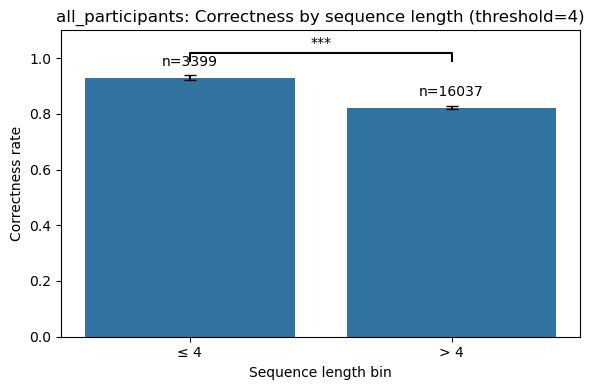

,group,n,k_correct,accuracy,ci_low,ci_high
0,≤ 4,3399,3160,0.930,0.921,0.938
1,> 4,16037,13179,0.822,0.816,0.828


,odds_ratio,p_value,delta_accuracy
0,2.867272,4.105724e-64,-0.107898


In [4]:
fig, summary, test = plot_correctness_by_sequence_len_threshold(
    df, threshold=4, h_or_g="all_participants", save=False
)
plt.show()
display(summary.round(3))
fisher_row(test)

The same question without a threshold: accuracy at each number of visits, with a 95% Wilson band. Trials with more than 40 visits are left out (`max_len=40`), and so is any number of visits with fewer than 5 trials (`min_n_per_len`). `run_all_correctness_seq_len_continuous_plots` draws it for each group.

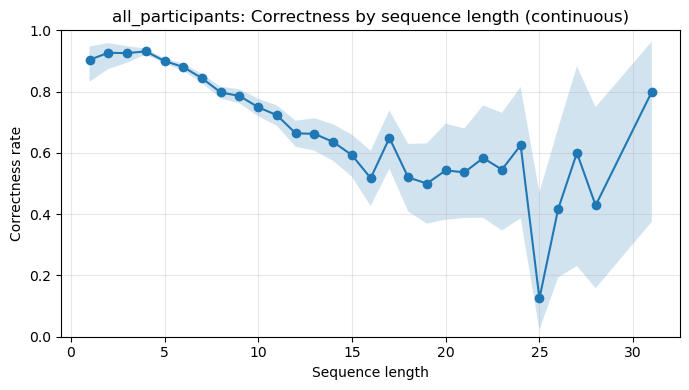

,seq_len,n,k_correct,accuracy,ci_low,ci_high
0,1,104,94,0.904,0.832,0.947
1,2,150,139,0.927,0.873,0.959
2,3,363,336,0.926,0.894,0.948
3,4,2782,2591,0.931,0.921,0.940
4,5,4668,4201,0.900,0.891,0.908
5,6,2839,2499,0.880,0.868,0.892
6,7,2310,1949,0.844,0.828,0.858
7,8,1688,1346,0.797,0.778,0.816
8,9,1218,957,0.786,0.762,0.808
9,10,877,657,0.749,0.719,0.777


In [5]:
fig, summary = plot_correctness_by_sequence_len_continuous(
    df, max_len=40, h_or_g="all_participants", save=False
)
plt.show()
summary.round(3).head(12)

## Back-and-forth at the end

Does a trial whose visits end by going back and forth between two areas have a different accuracy? XYX means the last three visits are x, y, x; XYXY that the last four are x, y, x, y. Any two areas count, the question included. The charts read like the one above; here the test's odds ratio is the odds of a correct answer with the pattern over the odds without it. `run_all_back_and_forth_pattern_plots` draws one pattern (`use_xyxy=`) for each group.

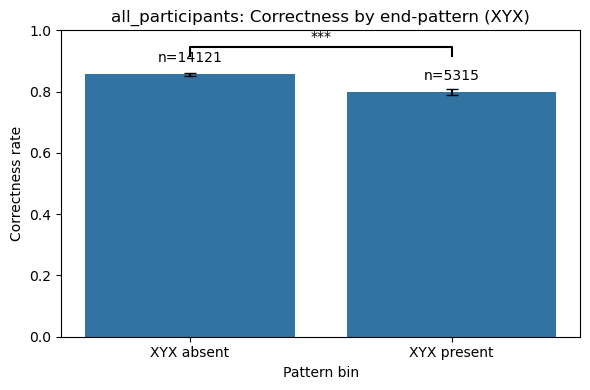

,group,n,k_correct,accuracy,ci_low,ci_high
0,XYX absent,14121,12090,0.856,0.850,0.862
1,XYX present,5315,4249,0.799,0.788,0.810


,odds_ratio,p_value,delta_accuracy
0,0.669596,3.321726e-21,-0.056736


In [6]:
fig, summary, test = plot_correctness_by_back_and_forth_pattern(
    df, use_xyxy=False, h_or_g="all_participants", save=False
)
plt.show()
display(summary.round(3))
fisher_row(test)

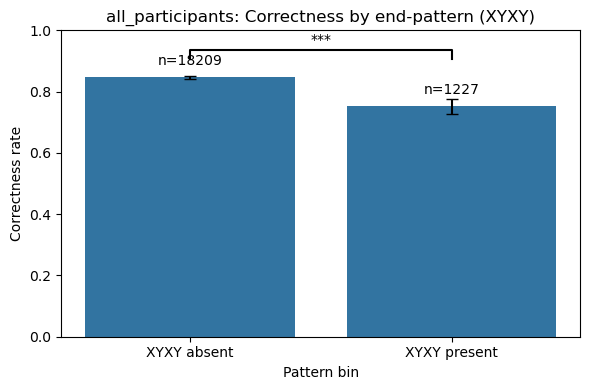

,group,n,k_correct,accuracy,ci_low,ci_high
0,XYXY absent,18209,15416,0.847,0.841,0.852
1,XYXY present,1227,923,0.752,0.727,0.776


,odds_ratio,p_value,delta_accuracy
0,0.550082,1.700520e-16,-0.094373


In [7]:
fig, summary, test = plot_correctness_by_back_and_forth_pattern(
    df, use_xyxy=True, h_or_g="all_participants", save=False
)
plt.show()
display(summary.round(3))
fisher_row(test)

## Mean dwell time per word

A trial's total looking time divided by the number of words on the answer screen, the question included; words never looked at count as 0 ms. The bars split trials at 100 ms per word (the test's odds ratio is low dwell over high dwell). The threshold is passed as a float (`100.0`), as the runner does: with a whole number the chart's labels match neither group and no bars are drawn.

`run_all_trial_mean_dwell_threshold_plots` draws thresholds of 50, 75 and 100 ms by default (`thresholds=`) for each group.

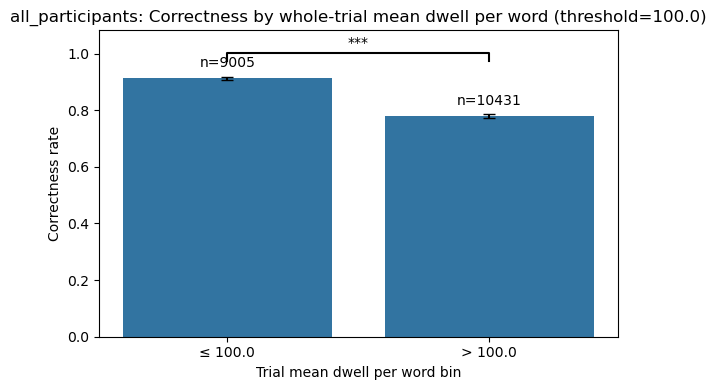

,group,n,k_correct,accuracy,ci_low,ci_high
0,≤ 100.0,9005,8213,0.912,0.906,0.918
1,> 100.0,10431,8126,0.779,0.771,0.787


,odds_ratio,p_value
0,2.941513,4.456300e-147


In [8]:
fig, summary, test = plot_correctness_by_trial_mean_dwell_threshold(
    df, threshold=100.0, h_or_g="all_participants", save=False
)
plt.show()
display(summary.round(3))
fisher_row(test)

The same measure without a threshold: accuracy in 10 ms bins (`bin_width`), with a 95% Wilson band. Trials above 700 ms per word are left out (`x_max=700`), and so are bins with fewer than 10 trials (`min_n_per_bin`). `run_all_trial_mean_dwell_continuous_plots` draws it for each group.

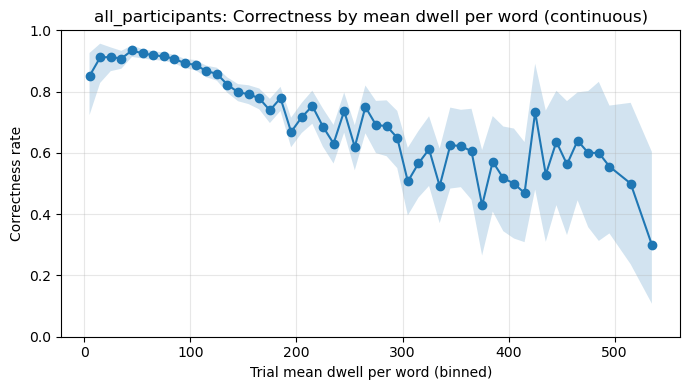

,_bin,n,k_correct,bin_left,bin_right,bin_center,accuracy,ci_low,ci_high
0,0,47,40,0.0,10.0,5.0,0.851,0.723,0.926
1,1,79,72,10.0,20.0,15.0,0.911,0.828,0.956
2,2,207,189,20.0,30.0,25.0,0.913,0.867,0.944
3,3,380,345,30.0,40.0,35.0,0.908,0.875,0.933
4,4,686,641,40.0,50.0,45.0,0.934,0.913,0.951
5,5,1156,1069,50.0,60.0,55.0,0.925,0.908,0.939
6,6,1431,1315,60.0,70.0,65.0,0.919,0.904,0.932
7,7,1695,1551,70.0,80.0,75.0,0.915,0.901,0.927
8,8,1657,1503,80.0,90.0,85.0,0.907,0.892,0.920
9,9,1662,1483,90.0,100.0,95.0,0.892,0.876,0.906


In [9]:
fig, summary = plot_correctness_by_trial_mean_dwell_continuous(
    df, bin_width=10.0, x_max=700, h_or_g="all_participants", save=False
)
plt.show()
summary.round(3).head(12)

## Time to answer

Accuracy against the time from the answers appearing to the confirming press, in 1-second bins (`bin_width=1.0`), with a 95% Wilson band. Trials over 30 seconds are left out (`x_max=30`; the count is printed below), and so are bins with fewer than 10 trials. `rt_col=Con.TOTAL_ANSWERING_RT_NORMALIZED` uses the time per word on the screen instead; `run_all_total_answering_rt_continuous_plots` draws it for each group.

trials over 30 s: 58


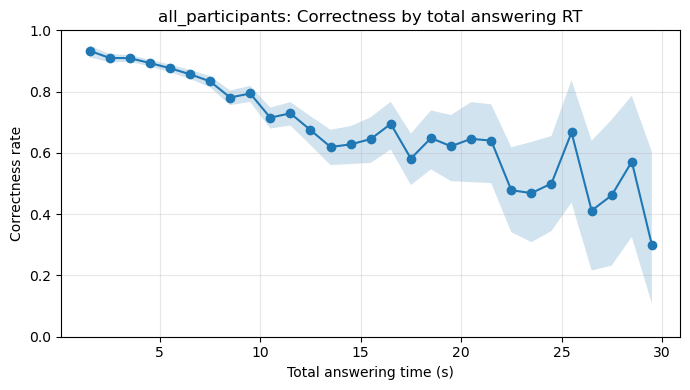

,bin_left,bin_right,bin_center,n,k_correct,accuracy,ci_low,ci_high
1,1.0,2.0,1.5,661,617,0.933,0.912,0.950
2,2.0,3.0,2.5,1730,1574,0.910,0.895,0.922
3,3.0,4.0,3.5,2610,2373,0.909,0.898,0.920
4,4.0,5.0,4.5,2994,2675,0.893,0.882,0.904
5,5.0,6.0,5.5,2703,2369,0.876,0.863,0.888
6,6.0,7.0,6.5,2116,1813,0.857,0.841,0.871
7,7.0,8.0,7.5,1592,1327,0.834,0.814,0.851
8,8.0,9.0,8.5,1131,883,0.781,0.756,0.804
9,9.0,10.0,9.5,912,724,0.794,0.766,0.819
10,10.0,11.0,10.5,663,474,0.715,0.679,0.748


In [10]:
print("trials over 30 s:", (trials[Con.CONFIRM_FINAL_ANSWER_RT] > 30_000).sum())
fig, summary = plot_correctness_by_total_answering_rt_continuous(
    df, bin_width=1.0, x_max=30, h_or_g="all_participants", save=False
)
plt.show()
summary.round(3).head(12)

## Did they choose the answer their eyes preferred?

For one measurement, `compute_trial_matching` picks the answer that stands out most on it and labels the trial "matching" if that is the answer chosen. Two ways of picking it: `polarity`, the answer with the highest value (or the lowest, for measures like skip rate), and `relative`, the answer furthest from the trial's average in either direction. Below, the measurement is mean dwell time, so with `polarity` the preferred answer is the one looked at longest. The table shows each trial's four values, the preferred answer (`pred_label`) and the one chosen.

In [11]:
matching = compute_trial_matching(df, metric_col=Con.MEAN_DWELL_TIME, direction="high", extreme_mode="polarity")
matching.round(1).head()

,TRIAL_INDEX,participant_id,selected_label,pred_label,pref_group,is_correct,A,B,C,D
0,3,l10_202,B,B,matching,0,198.8,353.0,146.3,185.0
1,3,l10_338,B,B,matching,0,932.0,1186.0,375.2,618.6
2,3,l10_341,A,A,matching,1,247.3,102.0,76.0,102.2
3,3,l10_39,D,A,not_matching,0,326.6,93.7,53.4,296.3
4,3,l11_342,A,A,matching,1,134.3,39.7,0.0,0.0


The bar chart compares the accuracy of matching and not-matching trials; the Fisher test is written at the top of the chart and shown below the table (the odds ratio is matching over not matching). `run_all_matching_correctness_plots` draws every measurement, both ways of picking, for each group.

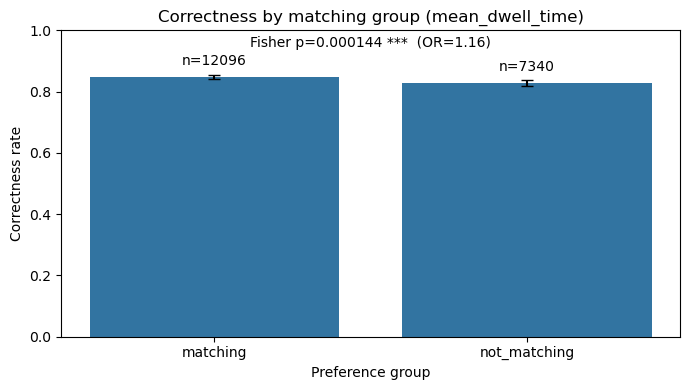

,pref_group,n_trials,n_correct,acc,ci_low,ci_high
0,matching,12096,10263,0.848,0.842,0.855
1,not_matching,7340,6076,0.828,0.819,0.836


,odds_ratio,p_value
0,1.164773,0.000144


In [12]:
summary = plot_correctness_by_matching(
    matching, metric_name=Con.MEAN_DWELL_TIME, mode="polarity", h_or_g="all_participants", save=False
)
plt.show()
display(summary.round(3))
fisher_row(correctness_by_pref_group_test(matching))

The same with the `relative` way of picking: the answer whose dwell time is furthest from the trial's average.

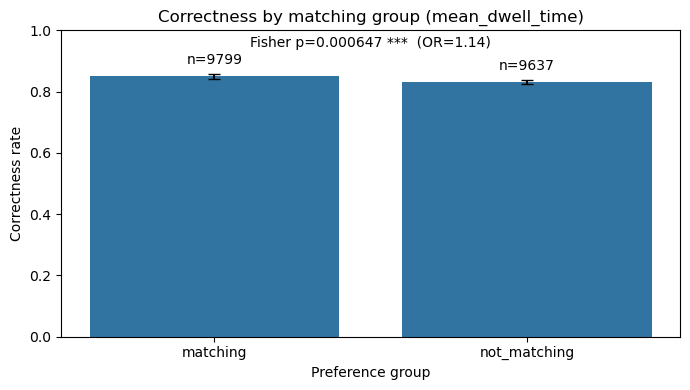

,pref_group,n_trials,n_correct,acc,ci_low,ci_high
0,matching,9799,8325,0.850,0.842,0.857
1,not_matching,9637,8014,0.832,0.824,0.839


,odds_ratio,p_value
0,1.143815,0.000647


In [13]:
matching_rel = compute_trial_matching(df, metric_col=Con.MEAN_DWELL_TIME, extreme_mode="relative")
summary = plot_correctness_by_matching(
    matching_rel, metric_name=Con.MEAN_DWELL_TIME, mode="relative", h_or_g="all_participants", save=False
)
plt.show()
display(summary.round(3))
fisher_row(correctness_by_pref_group_test(matching_rel))